In [250]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features 


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
# Selection des données
catalogue = data.catalogue          # DataFrame indexé par nom lisible
charger = data.charger              # Fonction de chargement de données

# Sélection du dataset
# DE + FE full
selection = data.selectionner(sources=("12kDE","12kFE",),
                                  defauts=("IR", "B", "OR"),
                                  diametres=(7, 14,21, ),
                                  positions_or=("6",),
                                  charges=(0, 1, 2, 3),
                                  avec_sains=True)


In [260]:
table = features.construire_table(selection, charger, canaux=("DE", "FE"))
# features.sauvegarder_table(table)                # écrit data/features/table_indicateurs.csv

INDICATEURS = indicateurs.COLONNES_TEMPORELS   # 4 indicateurs temporels (partie exploratoire)
# ORDRE = ["Sain", "IR007", "IR014", "IR021", "B007", "B014", "B021", "OR007", "OR014", "OR021"]


In [261]:
# table.iloc[70:100, :15]
table[table["canal"] == "FE"]

,fichier,fenetre,rpm,canal,numero,source,fs,defaut,position_OR,diametre_mils,...,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF,f_pic,classe
101,Normal_L0,0,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001018,0.006267,0.005233,0.006086,0.203094,0.285649,0.133188,0.378069,60.058594,Sain
102,Normal_L0,1,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.001319,0.004294,0.006015,0.006202,0.154014,0.332968,0.194814,0.318204,60.791016,Sain
103,Normal_L0,2,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000574,0.007760,0.007006,0.005637,0.067372,0.160511,0.171577,0.600541,60.058594,Sain
104,Normal_L0,3,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000867,0.003905,0.011645,0.013029,0.251415,0.253171,0.209546,0.285868,30.761719,Sain
105,Normal_L0,4,1796.0,FE,97,Normal,12000,Sain,NaN,0,...,0.000781,0.008527,0.009871,0.011672,0.199272,0.142502,0.173827,0.484400,31.494141,Sain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8017,12kFE_OR021at6_L0,45,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.063823,0.056750,0.586948,0.669555,0.109431,0.541788,0.284245,0.064536,30.029297,OR021
8018,12kFE_OR021at6_L0,46,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.028864,0.029306,0.318542,0.330890,0.199736,0.660242,0.098169,0.041853,91.552734,OR021
8019,12kFE_OR021at6_L0,47,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.022011,0.019165,0.560075,0.656948,0.174760,0.494200,0.310677,0.020363,30.029297,OR021
8020,12kFE_OR021at6_L0,48,1797.0,FE,315,12kFE,12000,OR,6,21,...,0.047168,0.030995,0.583986,0.674855,0.110190,0.549091,0.306058,0.034660,30.029297,OR021


In [279]:
display(table.groupby(["source", "classe", "canal"]).size().unstack())
table.defaut.unique()


canal           DE   FE
source classe          
12kDE  B007    201  201
       B014    200  200
       B021    200  200
       IR007   201  201
       IR014   200  200
       IR021   200  200
       OR007   202  202
       OR014   200  200
       OR021   201  201
12kFE  B007    200  200
       B014    200  200
       B021    200  200
       IR007   200  200
       IR014   200  200
       IR021   200  200
       OR007   200  200
       OR014    50   50
       OR021    50   50
Normal Sain    706  706

<StringArray>
['Sain', 'IR', 'B', 'OR']
Length: 4, dtype: str

In [281]:
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."

COLONNES_INDICATEURS = indicateurs.COLONNES_INDICATEURS
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")


# Équilibre UNIQUEMENT le train (le test reste complet)
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

,train,test
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


In [284]:
#| label: regression logistique
from sklearn import linear_model

logreg = linear_model.LogisticRegression(max_iter=500, random_state=24)
logregb = linear_model.LogisticRegression(max_iter=500, random_state=24, class_weight="balanced") ##  >> Pour gérer le déséquilibre de classes

logreg.fit(X_train, y_train)
logregb.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_predb = logregb.predict(X_test)
cm = pd.crosstab(y_test, y_pred, rownames=['Classe réelle'], colnames=['Classe prédite'])
cmb = pd.crosstab(y_test, y_predb, rownames=['Classe réelle'], colnames=['Classe prédite'])

In [285]:
#| label: regression logistique pour avoir une base, avec comparaison class_weight="balanced" ou non
from sklearn.metrics import classification_report
print("###### LogReg standard ######")
display(cm)
print(classification_report(y_test, y_pred))

print("###### LogReg class_weight=balanced ######")
display(cmb)
print(classification_report(y_test, y_predb))

###### LogReg standard ######


Classe prédite,B,IR,OR,Sain
Classe réelle,,,,
B,506,5,63,26
IR,338,262,0,0
OR,43,47,210,0
Sain,0,0,0,706


              precision    recall  f1-score   support

           B       0.57      0.84      0.68       600
          IR       0.83      0.44      0.57       600
          OR       0.77      0.70      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.74      2206
weighted avg       0.80      0.76      0.75      2206

###### LogReg class_weight=balanced ######


Classe prédite,B,IR,OR,Sain
Classe réelle,,,,
B,506,5,63,26
IR,338,262,0,0
OR,43,47,210,0
Sain,0,0,0,706


              precision    recall  f1-score   support

           B       0.57      0.84      0.68       600
          IR       0.83      0.44      0.57       600
          OR       0.77      0.70      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.74      2206
weighted avg       0.80      0.76      0.75      2206



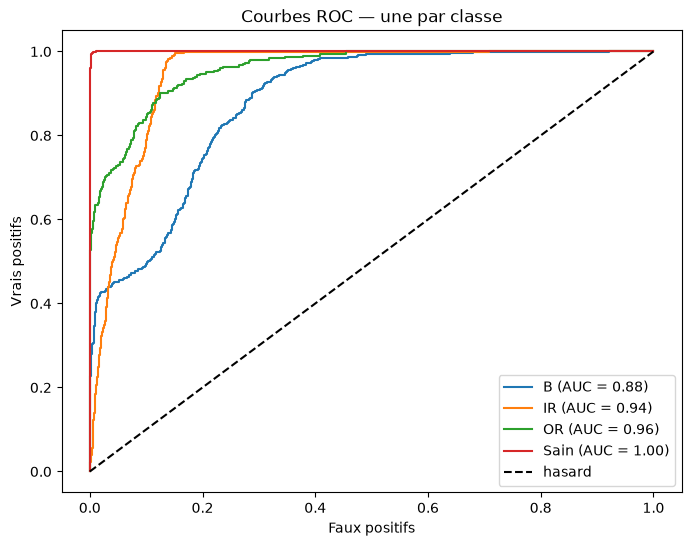

In [286]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Probabilités prédites (une colonne par classe)
probs = logreg.predict_proba(X_test)

# Vraies classes en 0/1 (une colonne par classe)
classes = logreg.classes_
y_bin = label_binarize(y_test, classes=classes)

# Courbes ROC par classe
plt.figure(figsize=(8, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")

plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Faux positifs")
plt.ylabel("Vrais positifs")
plt.title("Courbes ROC — une par classe")
plt.legend()
plt.show()

In [287]:
#| label: arbre de décision : def+fit
from sklearn.tree import DecisionTreeClassifier

Model_tree = DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=123)
Model_tree.fit(X_train, y_train)
y_pred = Model_tree.predict(X_test)

In [288]:
#| label: arbre de décision : results
display(pd.crosstab(y_test, y_pred, rownames=['real'], colnames=['pred']))

print(classification_report(y_test, y_pred))

feats = {}
for feature, importance in zip(X_test.columns, Model_tree.feature_importances_):
    feats[feature] = importance
importances = pd.DataFrame.from_dict(feats, orient='index')
importances = importances.rename(columns={0:'Importance'})
importances = importances.sort_values('Importance', ascending=False)
display(importances[importances['Importance'] != 0])
display(importances[importances['Importance'] == 0])

pred,B,IR,OR,Sain
real,,,,
B,493,4,103,0
IR,159,439,2,0
OR,32,0,268,0
Sain,249,0,28,429


              precision    recall  f1-score   support

           B       0.53      0.82      0.64       600
          IR       0.99      0.73      0.84       600
          OR       0.67      0.89      0.76       300
        Sain       1.00      0.61      0.76       706

    accuracy                           0.74      2206
   macro avg       0.80      0.76      0.75      2206
weighted avg       0.82      0.74      0.75      2206



,Importance
RMS,0.504485
ratio_BPFI,0.264477
amp_BPFO_3,0.115424
amp_BPFI_1,0.081115
Kurtosis,0.015298
amp_BPFO_1,0.005466
amp_FTF_3,0.004916
ratio_BSF,0.002153
amp_FTF_2,0.001864
amp_BPFI_3,0.001821


,Importance
Pic,0.0
Crete,0.0
amp_BSF_1,0.0
amp_BPFI_2,0.0
amp_FTF_1,0.0
ratio_BPFO,0.0
ratio_FTF,0.0
f_pic,0.0


,train,test
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


=== LogReg DE→FE ===
Accuracy          : 0.763
Balanced accuracy : 0.745
F1-macro          : 0.742

Rapport par classe :
              precision    recall  f1-score   support

           B       0.57      0.84      0.68       600
          IR       0.83      0.44      0.57       600
          OR       0.77      0.70      0.73       300
        Sain       0.96      1.00      0.98       706

    accuracy                           0.76      2206
   macro avg       0.78      0.74      0.74      2206
weighted avg       0.80      0.76      0.75      2206



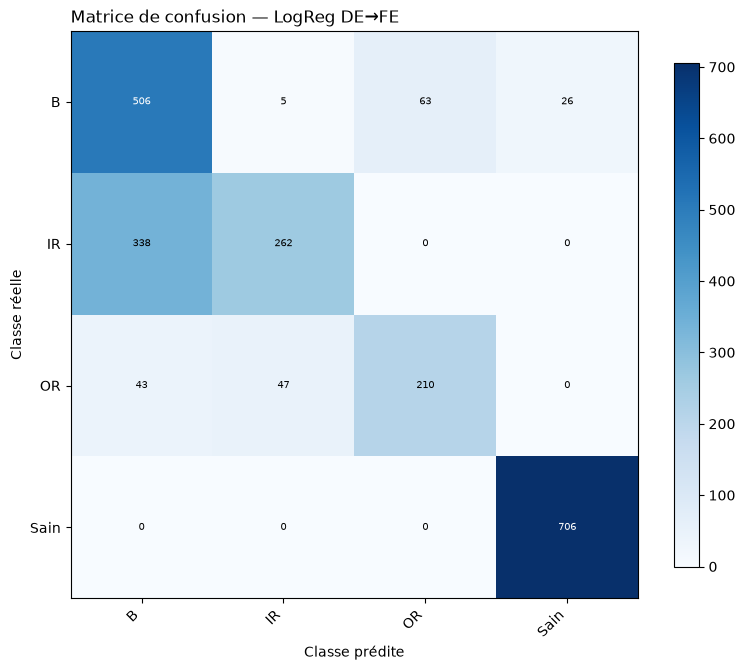

=== RF DE→FE ===
Accuracy          : 0.836
Balanced accuracy : 0.830
F1-macro          : 0.821

Rapport par classe :
              precision    recall  f1-score   support

           B       0.68      0.81      0.74       600
          IR       0.96      0.67      0.79       600
          OR       0.69      0.84      0.76       300
        Sain       1.00      1.00      1.00       706

    accuracy                           0.84      2206
   macro avg       0.83      0.83      0.82      2206
weighted avg       0.86      0.84      0.84      2206



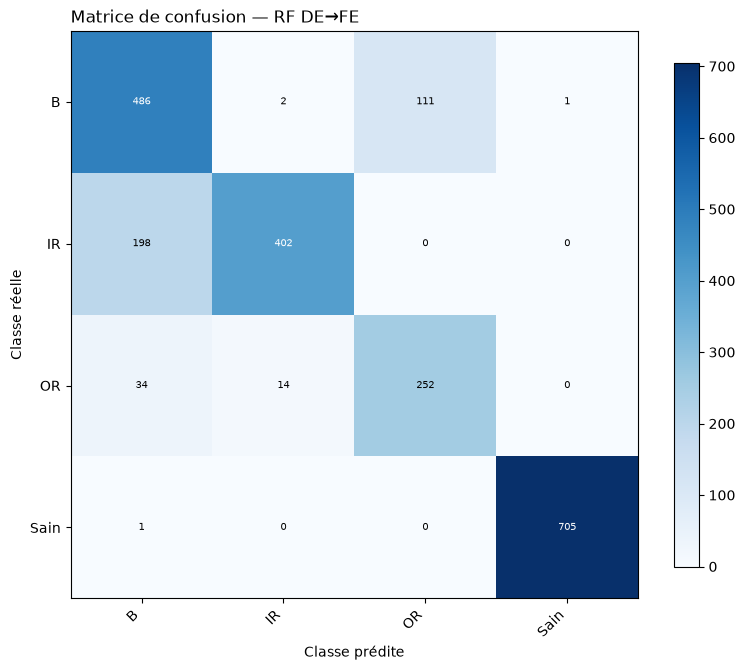

,modèle,accuracy,balanced_acc,F1-macro
0,LogReg DE→FE,0.763,0.745,0.742
1,RF DE→FE,0.836,0.830,0.821


In [283]:
# Cellule d'imports (avec les autres)
from Sources import data, features, indicateurs, models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Après ton split :
# X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, indicateurs.COLONNES_INDICATEURS)
X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target="defaut")

# Équilibre les datasets
X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

# Eval 1 model :
# logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
# logreg.fit(X_train, y_train)
# y_pred = logreg.predict(X_test)
# models.evaluer_modele(y_test, y_pred, classes=logreg.classes_, titre="LogReg DE→FE")

# compare plusieurs model
modeles = {
    "LogReg DE→FE": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "RF DE→FE": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1),
}
tableau = models.entrainer_comparer(modeles, X_train, y_train, X_test, y_test)
tableau   # affiche le DataFrame comparatif